# Figure 8

In [5]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_loo_comparison,
    load_robustness_loo,
    load_pupilacceptmodel_historyeffect_by_pupilbin,
    load_pupilacceptmodel_pupilbin_contrast,
    DATASET_LABELS,
)
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
BASELINE_MODEL = "HDDM_Base_Pupil"

### Helper functions

In [2]:
def sig_stars(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "n.s."


def add_significance_bracket(ax, x1, x2, y, h, p):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color="black", linewidth=1.2)
    ax.text((x1 + x2) / 2, y + h, sig_stars(p), ha="center", va="bottom")


def style_axis(ax, col=None, ylabel=None, xlabel=None, xlabel_col=1):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if col == 0 and ylabel:
        ax.set_ylabel(ylabel)
    if col == xlabel_col and xlabel:
        ax.set_xlabel(xlabel)


def compute_elpd_vs_baseline(dataset, baseline_model, model_order):
    """elpd_loo(model) - elpd_loo(baseline_model), computed directly from
    the raw elpd_loo column rather than the CSV's own elpd_diff -- elpd_diff
    is relative to whichever model ranks 0 in that dataset's comparison,
    which isn't always baseline_model (e.g. stpdrift isn't rank 0 in
    equalRange or sheng2020)."""
    loo = (load_loo_comparison(dataset, group_name="arousal")
           .set_index("model")["elpd_loo"])
    baseline_elpd = loo[baseline_model]
    return [loo[m] - baseline_elpd for m, _ in model_order]

def compute_elpd_robustness_vs_baseline(dataset, baseline_model, model_order,
                                        column="elpd_loo_reliable_only"):
    loo = load_robustness_loo(dataset, group_name = "arousal").set_index("model")[column]

    diffs = []
    for model_id, _ in model_order:
        diffs.append(loo[model_id] - loo[baseline_model])
    return diffs

ELPD_THRESHOLD = 4

ELPD_COLORS = {
    "improved":  "#017D01",
    "ambiguous": "#8D8D8D",
    "worse":     "#980B0B",
}
ELPD_LABELS = {
    "improved":  "∆elpd > 4",
    "ambiguous": "otherwise",
    "worse":     "∆elpd < -4",
}


def elpd_category(diff):
    if diff > ELPD_THRESHOLD:
        return "improved"
    if diff < -ELPD_THRESHOLD:
        return "worse"
    return "ambiguous"


def plot_elpd_bars(ax, diffs, x_labels, col, ylim, show_legend=False):
    x_pos = np.arange(len(diffs))
    colors = [ELPD_COLORS[elpd_category(d)] for d in diffs]
    ax.bar(x_pos, diffs, color=colors, width=0.6, zorder=3)
    ax.axhline(0, color="black", linestyle="--", linewidth=1.5, zorder=2)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels)
    ax.set_ylim(ylim)
    if col == 1:
        ax.set_xlabel("DDM parameter(s) with decision-related pupil interaction")
    style_axis(ax, col, ylabel="Improvement over\nChoice-History DDM (∆elpd-loo)")

    if show_legend:
        handles = [mpatches.Patch(facecolor=ELPD_COLORS[cat], label=ELPD_LABELS[cat])
                  for cat in ("improved", "worse", "ambiguous")]
        ax.legend(handles=handles, loc="upper left")

### Figure 8

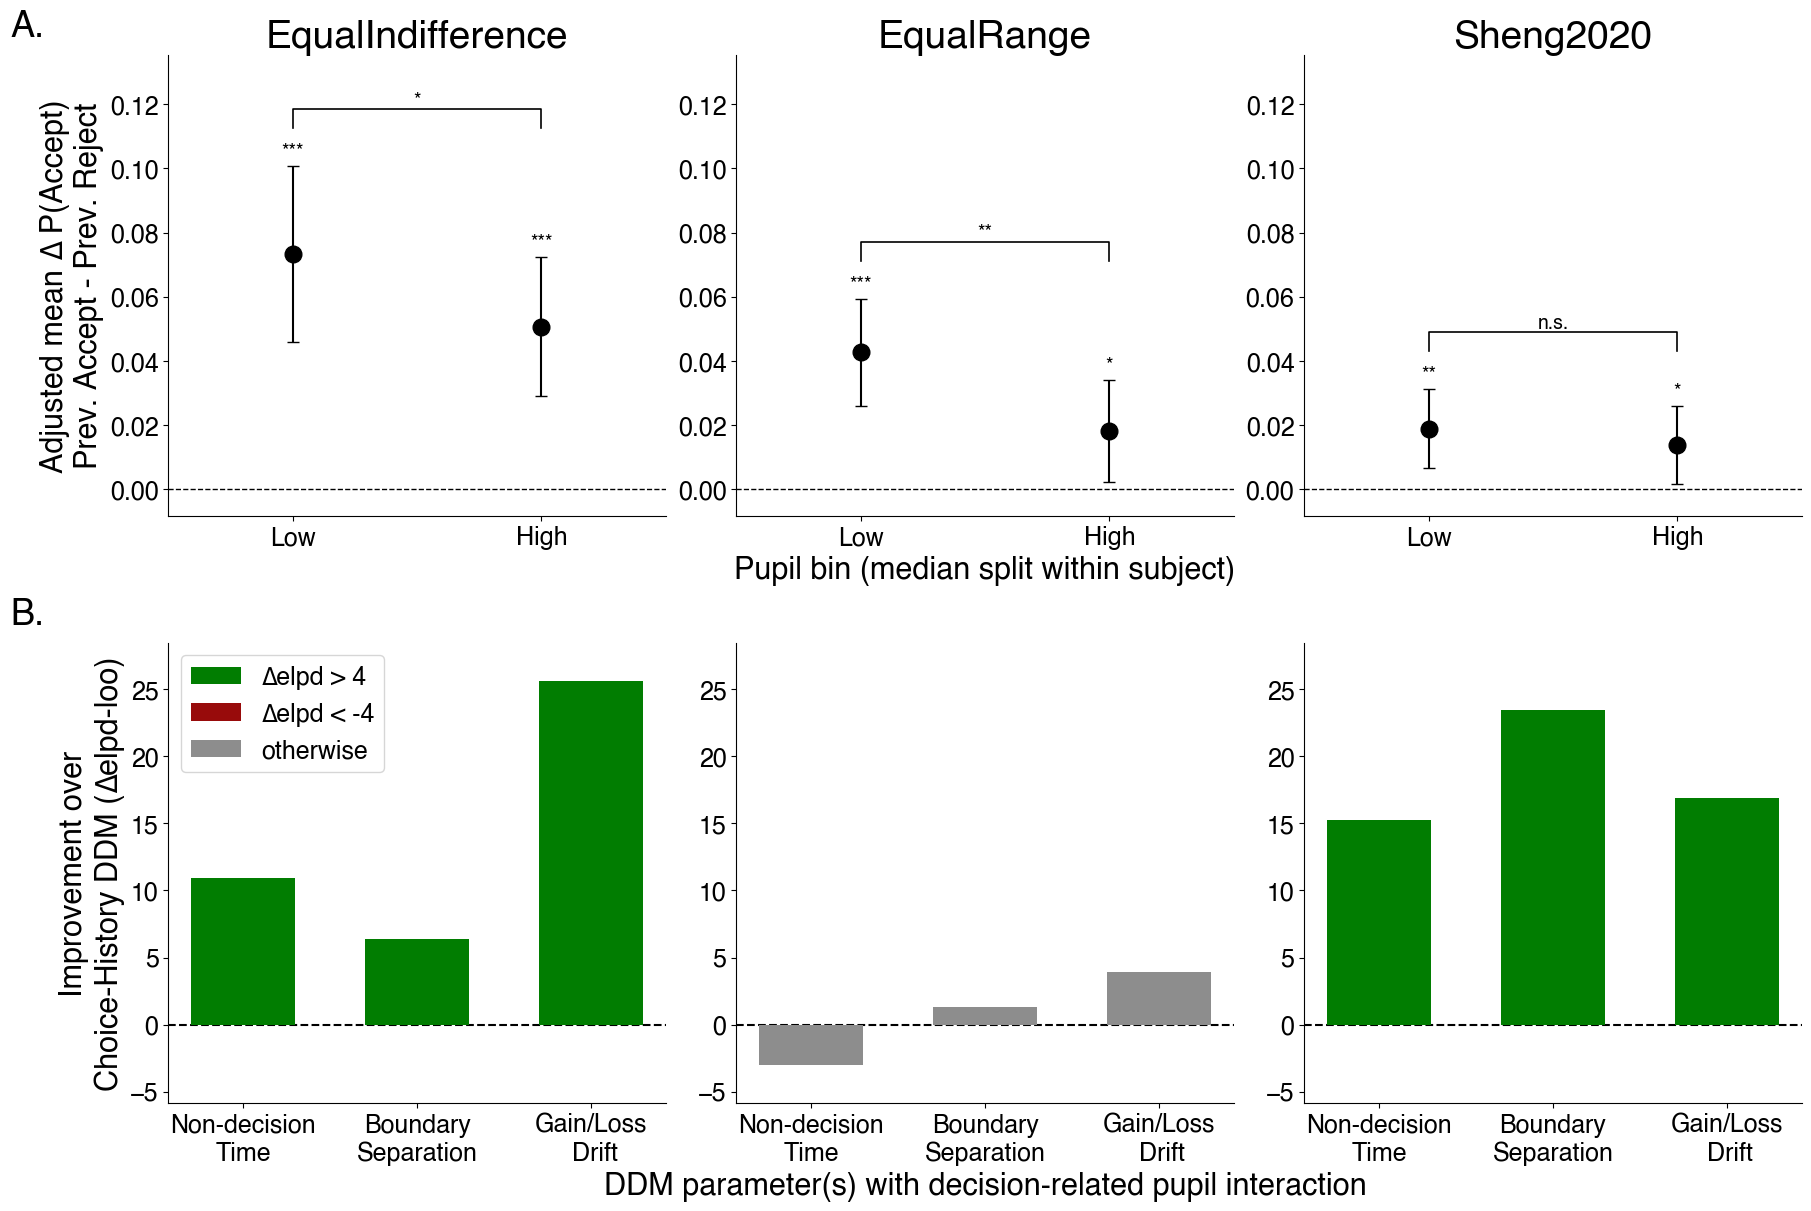

In [6]:
PUPIL_BIN_ORDER = ["Low", "High"]
HISTORYEFFECT_COLOR = "black"

historyeffect_by_pupilbin = load_pupilacceptmodel_historyeffect_by_pupilbin()
pupilbin_contrast = load_pupilacceptmodel_pupilbin_contrast()

hist_los = historyeffect_by_pupilbin["asymp.LCL"].values
hist_his = historyeffect_by_pupilbin["asymp.UCL"].values
hist_range = hist_his.max() - hist_los.min()
HISTORYEFFECT_YLIM = (hist_los.min() - 0.1 * hist_range, hist_his.max() + 0.35 * hist_range)

ELPD_MODEL_ORDER = [
    ("HDDM_Base_Pupil_ndt",       "Non-decision\nTime"),
    ("HDDM_Base_Pupil_boundary",  "Boundary\nSeparation"),
    ("HDDM_Base_Pupil_valuation", "Gain/Loss\n Drift")

]

elpd_labels = [label for _, label in ELPD_MODEL_ORDER]
elpd_vs_baseline = {ds: compute_elpd_vs_baseline(ds, BASELINE_MODEL, ELPD_MODEL_ORDER) for ds in DATASETS}

all_diffs = [d for diffs in elpd_vs_baseline.values() for d in diffs]
margin = 0.1 * (max(all_diffs) - min(all_diffs))
elpd_ylim = (min(all_diffs) - margin, max(all_diffs) + margin)

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12), layout="constrained")

for col, ds in enumerate(DATASETS):
    # --- Row A: choice-history effect by pupil bin ---
    ax = axes[0, col]
    x_pos = np.arange(len(PUPIL_BIN_ORDER))
    ds_hist = (
        historyeffect_by_pupilbin[historyeffect_by_pupilbin["dataset"] == ds]
        .set_index("pupil_bin").loc[PUPIL_BIN_ORDER]
    )
    ds_contrast_p = pupilbin_contrast.loc[pupilbin_contrast["dataset"] == ds, "p_adj_bh"].iloc[0]

    means = ds_hist["historyeffect"].values
    los   = ds_hist["asymp.LCL"].values
    his   = ds_hist["asymp.UCL"].values
    yerr  = [means - los, his - means]

    ax.errorbar(x_pos, means, yerr=yerr, fmt="o", color=HISTORYEFFECT_COLOR,
               markersize=12, capsize=4, elinewidth=1.5, zorder=2)
    ax.axhline(0, color="black", linewidth=1, linestyle="--", zorder=1)

    for x, y_top, p in zip(x_pos, his, ds_hist["p_adj_bh"]):
        ax.annotate(sig_stars(p), xy=(x, y_top), xytext=(0, 4),
                   textcoords="offset points", ha="center", va="bottom")

    bracket_y = his.max() + 0.12 * hist_range
    bracket_h = 0.06 * hist_range
    add_significance_bracket(ax, x_pos[0], x_pos[1], bracket_y, bracket_h, ds_contrast_p)

    ax.set_xlim(-0.5, len(PUPIL_BIN_ORDER) - 0.5)
    ax.set_ylim(*HISTORYEFFECT_YLIM)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(PUPIL_BIN_ORDER)
    ax.set_title(DATASET_LABELS.get(ds, ds))
    style_axis(ax, col, ylabel="Adjusted mean ∆ P(Accept)\nPrev. Accept - Prev. Reject",
              xlabel="Pupil bin (median split within subject)")

    # --- Row B: ELPD improvement over the full arousal DDM ---
    plot_elpd_bars(axes[1, col], elpd_vs_baseline[ds], elpd_labels, col, elpd_ylim, show_legend=(col == 0))
    # axes[1, col].set_title(DATASET_LABELS.get(ds, ds))

# Row labels, placed just outside the top-left corner of each row's leftmost
# panel (same convention as figure1.ipynb's "A."/"B."/"C.")
axes[0, 0].text(-0.25, 1.1, "A.", transform=axes[0, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[1, 0].text(-0.25, 1.1, "B.", transform=axes[1, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")

fig.savefig("saved/figure8.svg", dpi=300, bbox_inches="tight")
plt.show()

#### Robustness checks

In [4]:
ELPD_MODEL_ORDER_robust = [
    ("HDDM_Base_Lag1-stpdrift_Pupil_valuation", "Gain/Loss\n Drift"),
    ("HDDM_Base_Lag1-stpdrift_Pupil_boundary",  "Boundary\nSeparation"),
    ("HDDM_Base_Lag1-stpdrift_Pupil_stp",       "Starting\nPoint"),
    ("HDDM_Base_Lag1-stpdrift_Pupil_drift",     "Fixed\nDrift"),
]
elpd_vs_baseline_robust = {}
elpd_labels_robust = [label for _, label in ELPD_MODEL_ORDER_robust]
for ds in DATASETS:
    elpd_vs_baseline_robust[ds] = compute_elpd_vs_baseline(ds, "HDDM_Base_Lag1-stpdrift_Pupil", ELPD_MODEL_ORDER_robust)
    print(f"\n{ds}")
    robust_diffs = compute_elpd_robustness_vs_baseline(ds, "HDDM_Base_Lag1-stpdrift_Pupil", ELPD_MODEL_ORDER_robust)
    summary = pd.DataFrame({
        "model": elpd_labels_robust,
        "delta_elpd": elpd_vs_baseline_robust[ds],
        "delta_elpd_robust": robust_diffs,
    })
    print(summary.to_string(index=False))


equalIndifference
               model  delta_elpd  delta_elpd_robust
   Gain/Loss\n Drift   27.475643          29.013276
Boundary\nSeparation    8.811804          13.438360
     Starting\nPoint    4.847263          13.034067
        Fixed\nDrift   17.454762          20.598651

equalRange
               model  delta_elpd  delta_elpd_robust
   Gain/Loss\n Drift    4.793132           3.985497
Boundary\nSeparation    2.037163           2.901511
     Starting\nPoint    1.903863           1.376902
        Fixed\nDrift   -0.993936           0.060086

sheng2020
               model  delta_elpd  delta_elpd_robust
   Gain/Loss\n Drift   17.941592          15.826813
Boundary\nSeparation   22.960519          24.267384
     Starting\nPoint    0.921249          -2.053183
        Fixed\nDrift   13.908385          11.977005


In [7]:
ELPD_MODEL_ORDER_robust = [
    ("HDDM_Base_Lag1-stp_Pupil", "Choice History"),
]
elpd_vs_baseline_robust = {}
elpd_labels_robust = [label for _, label in ELPD_MODEL_ORDER_robust]
for ds in DATASETS:
    elpd_vs_baseline_robust[ds] = compute_elpd_vs_baseline(ds, "HDDM_Base_Pupil", ELPD_MODEL_ORDER_robust)
    print(f"\n{ds}")
    robust_diffs = compute_elpd_robustness_vs_baseline(ds, "HDDM_Base_Pupil", ELPD_MODEL_ORDER_robust)
    summary = pd.DataFrame({
        "model": elpd_labels_robust,
        "delta_elpd": elpd_vs_baseline_robust[ds],
        "delta_elpd_robust": robust_diffs,
    })
    print(summary.to_string(index=False))


equalIndifference
         model  delta_elpd  delta_elpd_robust
Choice History   71.268302          59.426419

equalRange
         model  delta_elpd  delta_elpd_robust
Choice History   24.726943          23.312064

sheng2020
         model  delta_elpd  delta_elpd_robust
Choice History  106.273388          87.388347


In [8]:
ELPD_MODEL_ORDER_robust = [
    ("HDDM_Base_Lag1-drift_Pupil", "Choice History"),
]
elpd_vs_baseline_robust = {}
elpd_labels_robust = [label for _, label in ELPD_MODEL_ORDER_robust]
for ds in DATASETS:
    elpd_vs_baseline_robust[ds] = compute_elpd_vs_baseline(ds, "HDDM_Base_Pupil", ELPD_MODEL_ORDER_robust)
    print(f"\n{ds}")
    robust_diffs = compute_elpd_robustness_vs_baseline(ds, "HDDM_Base_Pupil", ELPD_MODEL_ORDER_robust)
    summary = pd.DataFrame({
        "model": elpd_labels_robust,
        "delta_elpd": elpd_vs_baseline_robust[ds],
        "delta_elpd_robust": robust_diffs,
    })
    print(summary.to_string(index=False))


equalIndifference
         model  delta_elpd  delta_elpd_robust
Choice History    61.10845           59.38789

equalRange
         model  delta_elpd  delta_elpd_robust
Choice History   10.146366          12.372202

sheng2020
         model  delta_elpd  delta_elpd_robust
Choice History   20.417033          20.798487
